NAME: Keerthi N

REG NO: 2411021240024

SUBJECT: Deep Learning

# Project 12: Understanding Convolution and Pooling

## Aim
To understand how convolution and pooling operations work on images and how they help Convolutional Neural Networks (CNNs) extract important features.

## Objectives
1. Load a sample image using Python.
2. Apply different convolution filters to the image.
3. Apply different pooling operations.
4. Visualize the original image and generated feature maps.
5. Compare the effect of different filters and pooling techniques.
6. Understand how CNNs use convolution and pooling to extract important image features.

## Introduction

Convolution and pooling are important operations used in Convolutional Neural Networks (CNNs).

Convolution applies a small matrix called a filter or kernel to an image. The filter moves across the image and detects specific features such as edges, lines, textures, and patterns.

The result of applying a filter to an image is called a feature map.

Pooling reduces the size of the feature map while keeping important information. Common pooling techniques include Max Pooling and Average Pooling.

In this project, different convolution filters and pooling operations are applied to a sample image and their effects are visualized.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import convolve
from skimage import data, color

## Task 1: Load a Sample Image

A sample grayscale image is loaded using the scikit-image library.

A grayscale image contains intensity values ranging from black to white. These values can be represented as a matrix of numbers.

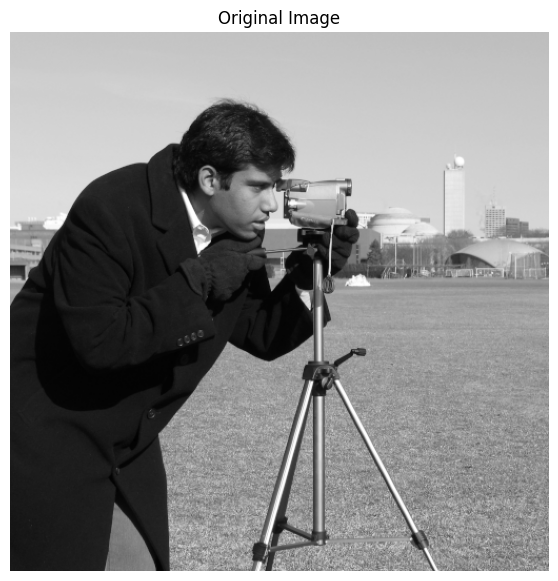

In [2]:
# Load a sample image
image = data.camera()

# Display image
plt.figure(figsize=(7, 7))
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")
plt.show()

## Image Information

Before applying convolution, we check the size and pixel values of the image.

An image is represented as a matrix where each value represents the intensity of a pixel.

In [3]:
print("Image shape:", image.shape)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

Image shape: (512, 512)
Minimum pixel value: 0
Maximum pixel value: 255


## What is Convolution?

Convolution is an operation where a small matrix called a kernel or filter moves across an image.

At every position, the values of the image pixels are multiplied by the corresponding values of the filter. The results are added together to produce a new pixel value.

The filter helps detect particular features in the image.

For example:
- Edge detection filters detect edges.
- Blur filters smooth the image.
- Sharpening filters enhance details.

The output obtained after convolution is called a feature map.

## Creating Convolution Filters

Different filters can detect different types of information from an image.

In this project, we use:

1. Edge Detection Filter
2. Blur Filter
3. Sharpening Filter

Each filter produces a different feature map.

In [4]:
# Edge detection filter
edge_filter = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Blur filter
blur_filter = np.array([
    [1/9, 1/9, 1/9],
    [1/9, 1/9, 1/9],
    [1/9, 1/9, 1/9]
])

# Sharpening filter
sharpen_filter = np.array([
    [0, -1,  0],
    [-1, 5, -1],
    [0, -1,  0]
])

print("Edge Detection Filter:")
print(edge_filter)

print("\nBlur Filter:")
print(blur_filter)

print("\nSharpening Filter:")
print(sharpen_filter)

Edge Detection Filter:
[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]

Blur Filter:
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]

Sharpening Filter:
[[ 0 -1  0]
 [-1  5 -1]
 [ 0 -1  0]]


## Applying Edge Detection Filter

The edge detection filter emphasizes areas where there is a large difference between neighboring pixels.

Therefore, it highlights important boundaries and edges present in the image.

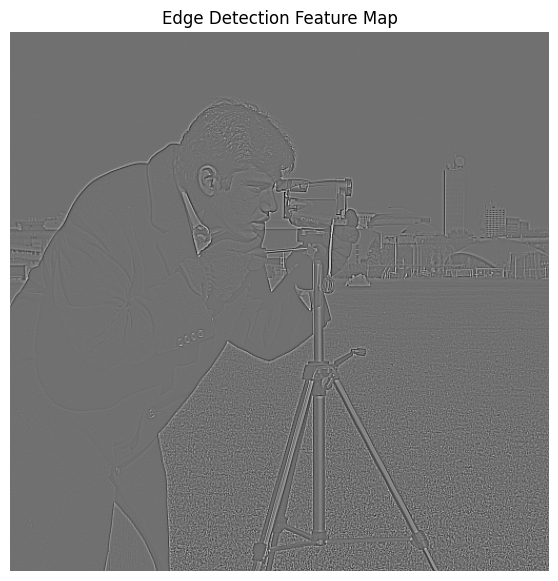

In [5]:
edge_feature_map = convolve(image.astype(float), edge_filter)

plt.figure(figsize=(7, 7))
plt.imshow(edge_feature_map, cmap='gray')
plt.title("Edge Detection Feature Map")
plt.axis("off")
plt.show()

## Applying Blur Filter

The blur filter averages nearby pixel values.

This reduces sharp changes and makes the image smoother.

Blur filters are useful for reducing noise and smoothing an image.

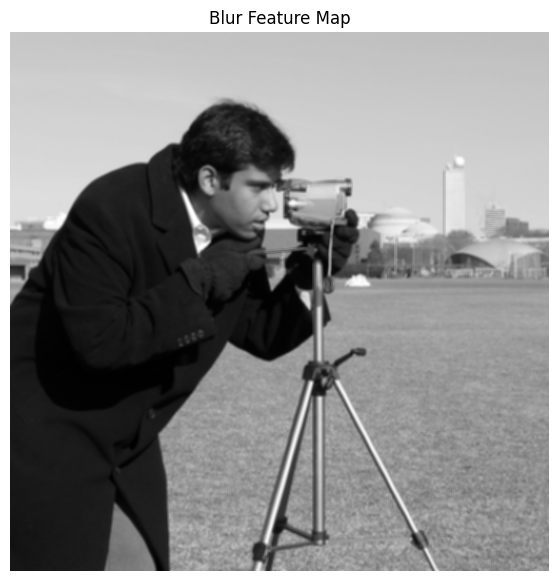

In [6]:
 blur_feature_map = convolve(image.astype(float), blur_filter)

plt.figure(figsize=(7, 7))
plt.imshow(blur_feature_map, cmap='gray')
plt.title("Blur Feature Map")
plt.axis("off")
plt.show()

## Applying Sharpening Filter

The sharpening filter increases the difference between neighboring pixels.

This makes edges and fine details appear more prominent.

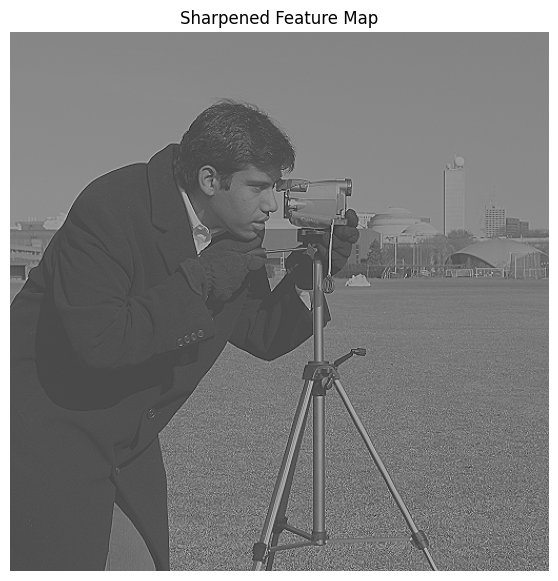

In [7]:
sharpen_feature_map = convolve(image.astype(float), sharpen_filter)

plt.figure(figsize=(7, 7))
plt.imshow(sharpen_feature_map, cmap='gray')
plt.title("Sharpened Feature Map")
plt.axis("off")
plt.show()

## Comparison of Convolution Filters

Different filters produce different feature maps from the same original image.

The edge detection filter highlights boundaries, the blur filter smooths the image, and the sharpening filter enhances details.

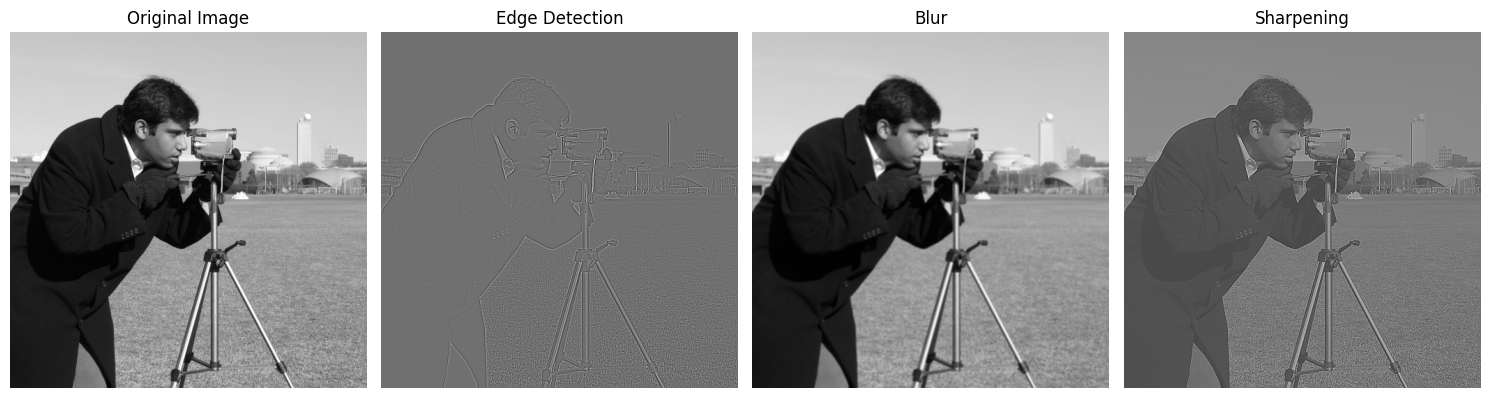

In [8]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(edge_feature_map, cmap='gray')
plt.title("Edge Detection")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(blur_feature_map, cmap='gray')
plt.title("Blur")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(sharpen_feature_map, cmap='gray')
plt.title("Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()

## Feature Map

A feature map is the output produced after applying a convolution filter to an image.

Different filters produce different feature maps because each filter looks for a different type of pattern.

For example:

- An edge filter produces a map showing edges.
- A blur filter produces a smoother representation.
- A sharpening filter emphasizes fine details.

CNNs learn many such filters automatically during training.

## Pooling

Pooling is used to reduce the spatial size of a feature map.

It helps:
- Reduce the amount of computation.
- Reduce the size of the data.
- Keep important features.
- Make the network less sensitive to small changes in position.

Two common pooling techniques are:

1. Max Pooling
2. Average Pooling

## Max Pooling

Max pooling selects the largest value from a small region of the feature map.

For example, if a 2 × 2 region contains:

1  5
3  2

Max pooling selects:

5

Max pooling is useful because strong features such as edges can be preserved while reducing the image size.

In [9]:
def max_pooling(image, pool_size=2, stride=2):
    height, width = image.shape

    new_height = height // pool_size
    new_width = width // pool_size

    pooled = np.zeros((new_height, new_width))

    for i in range(new_height):
        for j in range(new_width):
            region = image[
                i * stride:i * stride + pool_size,
                j * stride:j * stride + pool_size
            ]

            pooled[i, j] = np.max(region)

    return pooled

Original image shape: (512, 512)
Max pooled image shape: (256, 256)


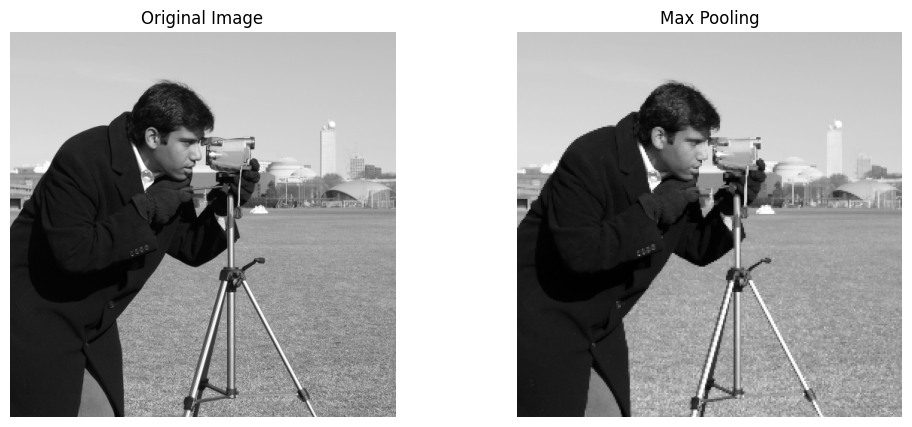

In [10]:
max_pooled = max_pooling(image)

print("Original image shape:", image.shape)
print("Max pooled image shape:", max_pooled.shape)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(max_pooled, cmap='gray')
plt.title("Max Pooling")
plt.axis("off")

plt.show()

## Average Pooling

Average pooling calculates the average value of the pixels in a small region.

For example, if the region contains:

2  4
6  8

Average pooling calculates:

(2 + 4 + 6 + 8) / 4 = 5

Therefore, the output value is 5.

In [11]:
def average_pooling(image, pool_size=2, stride=2):
    height, width = image.shape

    new_height = height // pool_size
    new_width = width // pool_size

    pooled = np.zeros((new_height, new_width))

    for i in range(new_height):
        for j in range(new_width):
            region = image[
                i * stride:i * stride + pool_size,
                j * stride:j * stride + pool_size
            ]

            pooled[i, j] = np.mean(region)

    return pooled

Original image shape: (512, 512)
Average pooled image shape: (256, 256)


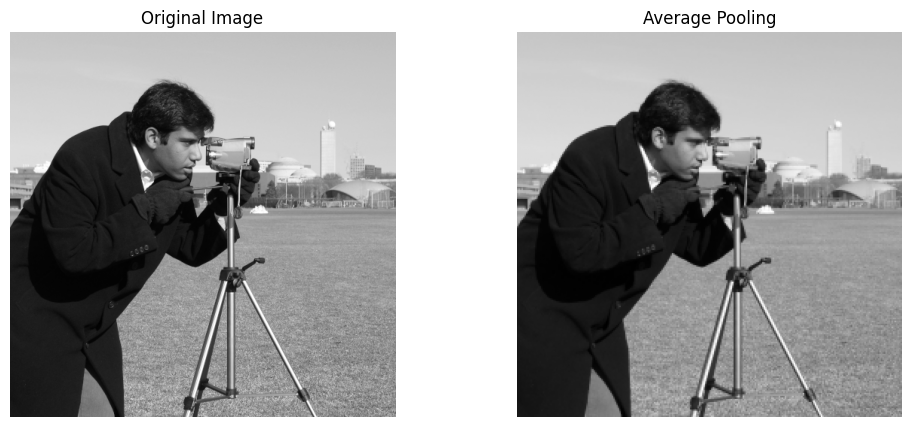

In [12]:
average_pooled = average_pooling(image)

print("Original image shape:", image.shape)
print("Average pooled image shape:", average_pooled.shape)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(average_pooled, cmap='gray')
plt.title("Average Pooling")
plt.axis("off")

plt.show()

## Comparison of Pooling Techniques

Max pooling selects the maximum value from each region, so strong features are preserved.

Average pooling calculates the average value, producing a smoother representation.

Both techniques reduce the spatial dimensions of the image.

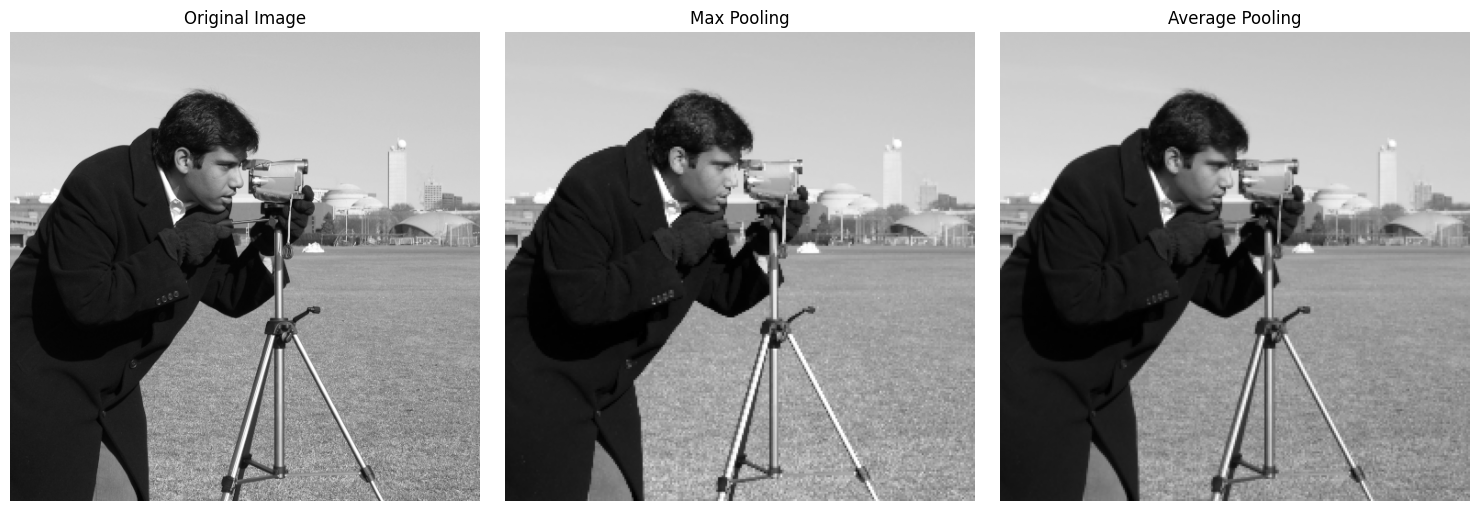

In [13]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(max_pooled, cmap='gray')
plt.title("Max Pooling")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(average_pooled, cmap='gray')
plt.title("Average Pooling")
plt.axis("off")

plt.tight_layout()
plt.show()

## Convolution Followed by Pooling

In a typical CNN, convolution is performed first to extract important features.

The resulting feature map is then passed through a pooling operation to reduce its spatial dimensions.

The general process is:

Input Image → Convolution → Feature Map → Pooling → Reduced Feature Map

In [14]:
# Apply edge detection
edge_feature_map = convolve(image.astype(float), edge_filter)

# Apply max pooling to the edge feature map
pooled_edge_map = max_pooling(edge_feature_map)

print("Original image shape:", image.shape)
print("Feature map shape:", edge_feature_map.shape)
print("Pooled feature map shape:", pooled_edge_map.shape)

Original image shape: (512, 512)
Feature map shape: (512, 512)
Pooled feature map shape: (256, 256)


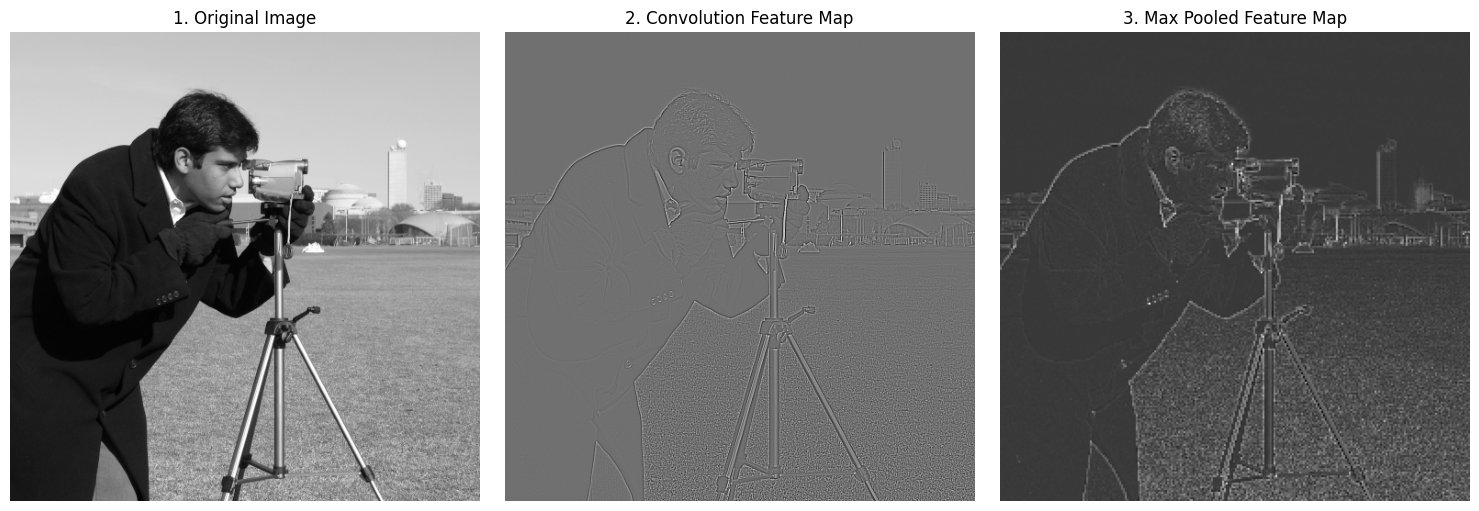

In [15]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("1. Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(edge_feature_map, cmap='gray')
plt.title("2. Convolution Feature Map")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pooled_edge_map, cmap='gray')
plt.title("3. Max Pooled Feature Map")
plt.axis("off")

plt.tight_layout()
plt.show()

## Final Comparison

The original image contains all the visual information.

After convolution, different filters extract different types of information from the image.

The edge detection filter emphasizes boundaries and edges.

The blur filter smooths the image by averaging neighboring pixels.

The sharpening filter enhances important details.

After pooling, the spatial dimensions are reduced while important information is retained.

Therefore, convolution helps in feature extraction and pooling helps in dimensionality reduction.

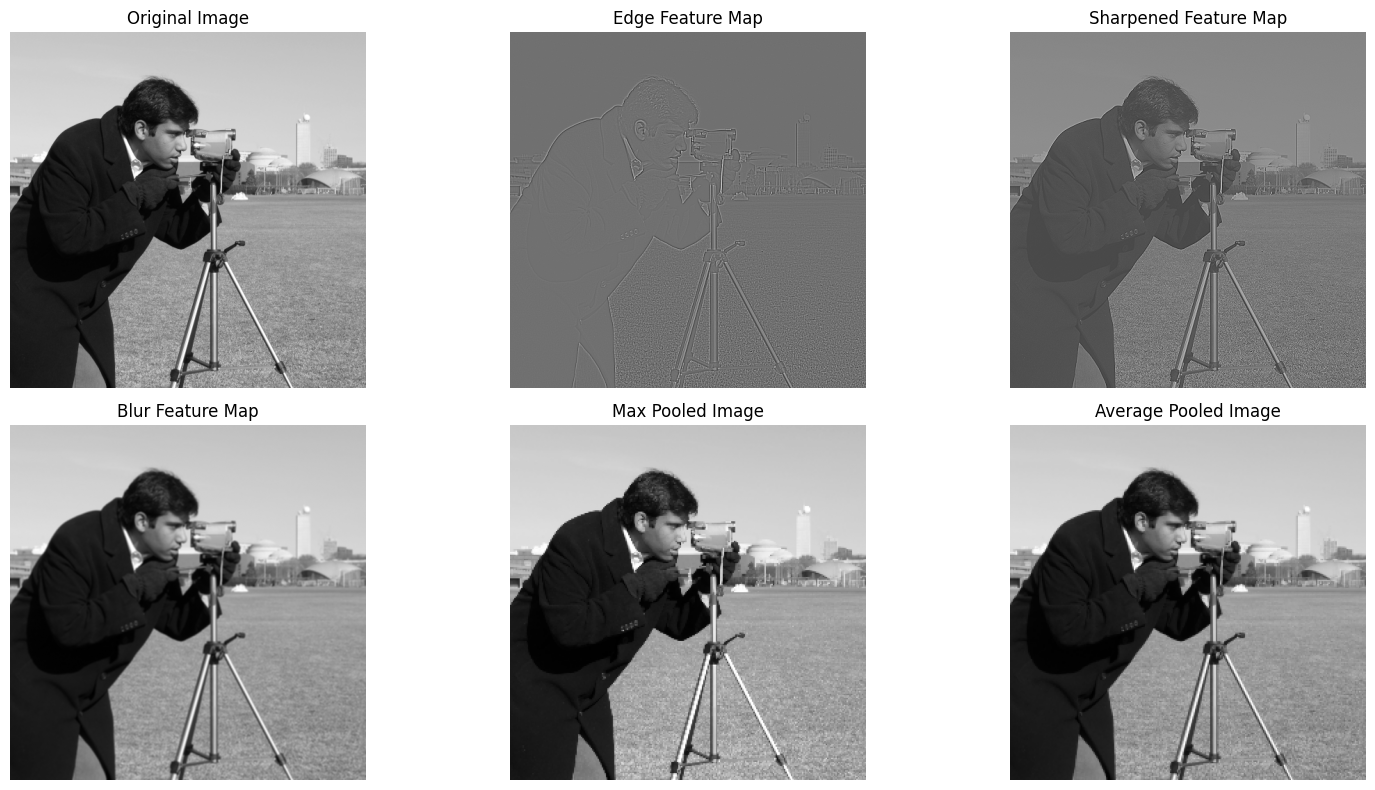

In [16]:
plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(edge_feature_map, cmap='gray')
plt.title("Edge Feature Map")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sharpen_feature_map, cmap='gray')
plt.title("Sharpened Feature Map")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(blur_feature_map, cmap='gray')
plt.title("Blur Feature Map")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(max_pooled, cmap='gray')
plt.title("Max Pooled Image")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(average_pooled, cmap='gray')
plt.title("Average Pooled Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## Observations

1. The original image contains the complete visual information.

2. The edge detection filter highlights the boundaries and edges present in the image.

3. The blur filter smooths the image and reduces sharp variations.

4. The sharpening filter enhances edges and fine details.

5. Max pooling reduces the image size while preserving strong pixel values and important features.

6. Average pooling reduces the image size by calculating the average value of each region.

7. Convolution produces feature maps that contain useful information extracted from the original image.

8. Pooling reduces spatial dimensions and computational requirements.

9. Convolution and pooling together form important components of Convolutional Neural Networks.

## Conclusion

In this project, convolution and pooling operations were implemented using Python.

Different convolution filters were applied to a sample image to observe how different features such as edges, smooth regions, and fine details can be extracted.

Max pooling and average pooling were then applied to reduce the spatial dimensions of the image.

The experiment shows that convolution is mainly used for feature extraction, while pooling is used for dimensionality reduction while retaining important information.

These operations are fundamental components of Convolutional Neural Networks (CNNs), which are widely used for image classification, object detection, image recognition, and other computer vision tasks.